<a href="https://colab.research.google.com/github/martinAguirreRuiz/TP2-IA-Hormigon-Grupo3/blob/main/TP2_Hormigon_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q xlrd
import pandas as pd

df = pd.read_excel('Concrete_Data.xls')
df.columns = ['cemento', 'escoria', 'cenizas', 'agua', 'superplast',
              'agr_grueso', 'agr_fino', 'edad', 'resistencia']

print('Filas y columnas:', df.shape)
print('Duplicados:', df.duplicated().sum())
df.head()

Filas y columnas: (1030, 9)
Duplicados: 25


,cemento,escoria,cenizas,agua,superplast,agr_grueso,agr_fino,edad,resistencia
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
from sklearn.model_selection import train_test_split

# 1) Sacar las filas repetidas
datos = df.drop_duplicates().reset_index(drop=True)
print('Sin duplicados:', len(datos))

# 2) Etiquetar cada ensayo con su clase de resistencia (C1 a C5)
datos['clase'] = pd.cut(datos['resistencia'],
                        bins=[0, 20, 30, 40, 50, 100],
                        labels=['C1', 'C2', 'C3', 'C4', 'C5'],
                        right=False)

# 3) Dividir: primero se aparta el 20% para prueba...
resto, prueba = train_test_split(datos, test_size=0.20,
                                 stratify=datos['clase'], random_state=42)
# ...y del 80% que queda, se aparta un octavo para validación
entren, valid = train_test_split(resto, test_size=0.125,
                                 stratify=resto['clase'], random_state=42)

print('Entrenamiento:', len(entren), '| Validación:', len(valid), '| Prueba:', len(prueba))

pd.DataFrame({'Entrenamiento': entren['clase'].value_counts(),
              'Validación': valid['clase'].value_counts(),
              'Prueba': prueba['clase'].value_counts()}).sort_index()

Sin duplicados: 1005
Entrenamiento: 703 | Validación: 101 | Prueba: 201


,Entrenamiento,Validación,Prueba
clase,,,
C1,137,20,39
C2,141,20,40
C3,173,25,50
C4,117,17,33
C5,135,19,39


In [4]:
from sklearn.preprocessing import MinMaxScaler

entradas = ['cemento', 'escoria', 'cenizas', 'agua', 'superplast',
            'agr_grueso', 'agr_fino', 'edad']

# El escalador aprende el mínimo y el máximo de cada columna,
# mirando SOLO los datos de entrenamiento
escalador = MinMaxScaler()
escalador.fit(entren[entradas])

# Con esa misma escala se transforman los tres grupos
X_entren = escalador.transform(entren[entradas])
X_valid  = escalador.transform(valid[entradas])
X_prueba = escalador.transform(prueba[entradas])

# Lo que queremos predecir: la resistencia, sin tocar
y_entren = entren['resistencia'].values
y_valid  = valid['resistencia'].values
y_prueba = prueba['resistencia'].values

pd.DataFrame(X_entren[:5], columns=entradas).round(2)

,cemento,escoria,cenizas,agua,superplast,agr_grueso,agr_fino,edad
0,0.74,0.06,0.66,0.37,0.28,0.06,0.39,0.07
1,0.25,0.00,0.61,0.47,0.18,0.77,0.46,0.04
2,0.74,0.14,0.00,0.85,0.00,0.39,0.00,0.02
3,0.21,0.00,0.50,0.39,0.23,0.59,0.77,0.27
4,0.45,0.00,0.53,0.34,0.40,0.46,0.48,0.07


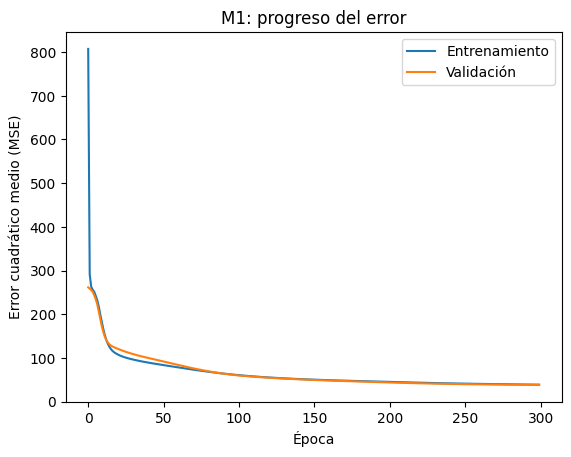

In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

# M1: 8 entradas -> 8 neuronas ocultas (sigmoide) -> 1 salida (lineal)
m1 = tf.keras.Sequential([
    tf.keras.Input(shape=(8,)),
    tf.keras.layers.Dense(8, activation='sigmoid'),
    tf.keras.layers.Dense(1)
])

m1.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9),
           loss='mse')

hist1 = m1.fit(X_entren, y_entren,
               validation_data=(X_valid, y_valid),
               epochs=300, batch_size=32, verbose=0)

plt.plot(hist1.history['loss'], label='Entrenamiento')
plt.plot(hist1.history['val_loss'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Error cuadrático medio (MSE)')
plt.title('M1: progreso del error')
plt.legend()
plt.show()

In [6]:
import numpy as np
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)

def metricas(modelo, X, y):
    pred = modelo.predict(X, verbose=0).ravel()
    return {'Error absoluto medio (MPa)': mean_absolute_error(y, pred),
            'Error relativo medio (%)': 100 * mean_absolute_percentage_error(y, pred),
            'RMSE (MPa)': np.sqrt(mean_squared_error(y, pred)),
            'R²': r2_score(y, pred)}

tabla_m1 = pd.DataFrame({'Entrenamiento': metricas(m1, X_entren, y_entren),
                         'Prueba': metricas(m1, X_prueba, y_prueba)}).round(2)
display(tabla_m1)

# Algunos ejemplos del examen final: valor real vs. lo que predijo M1
pred_prueba = m1.predict(X_prueba, verbose=0).ravel()
ejemplos = pd.DataFrame({'Real (MPa)': y_prueba[:8],
                         'Predicho por M1 (MPa)': pred_prueba[:8]})
ejemplos['Diferencia'] = ejemplos['Predicho por M1 (MPa)'] - ejemplos['Real (MPa)']
ejemplos.round(1)

,Entrenamiento,Prueba
Error absoluto medio (MPa),4.77,4.36
Error relativo medio (%),16.23,14.55
RMSE (MPa),6.22,6.00
R²,0.85,0.87


,Real (MPa),Predicho por M1 (MPa),Diferencia
0,32.1,34.900002,2.8
1,15.1,22.900000,7.8
2,23.5,25.100000,1.5
3,29.9,31.200001,1.3
4,42.3,43.900002,1.6
5,13.6,12.200000,-1.4
6,31.8,31.200001,-0.6
7,45.1,44.200001,-0.9


In [7]:
def agregar_atributos(d):
    d = d.copy()
    d['rel_ac'] = d['agua'] / d['cemento']     # relación agua/cemento
    d['log_edad'] = np.log(d['edad'])          # edad en escala logarítmica
    return d

entren2 = agregar_atributos(entren)
valid2  = agregar_atributos(valid)
prueba2 = agregar_atributos(prueba)

# Las entradas de M2: la edad original se reemplaza por su logaritmo,
# y se suma la relación agua/cemento. Quedan 9 entradas.
entradas2 = ['cemento', 'escoria', 'cenizas', 'agua', 'superplast',
             'agr_grueso', 'agr_fino', 'log_edad', 'rel_ac']

escalador2 = MinMaxScaler().fit(entren2[entradas2])
X2_entren = escalador2.transform(entren2[entradas2])
X2_valid  = escalador2.transform(valid2[entradas2])
X2_prueba = escalador2.transform(prueba2[entradas2])

entren2[['cemento', 'agua', 'rel_ac', 'edad', 'log_edad', 'resistencia']].head().round(2)

,cemento,agua,rel_ac,edad,log_edad,resistencia
485,424.00,168.00,0.40,28,3.33,72.10
181,212.07,180.31,0.85,14,2.64,20.92
45,427.50,228.00,0.53,7,1.95,35.08
445,194.68,170.17,0.87,100,4.61,44.28
888,298.00,164.00,0.55,28,3.33,35.86


Épocas entrenadas: 394 | Mejor época: 294


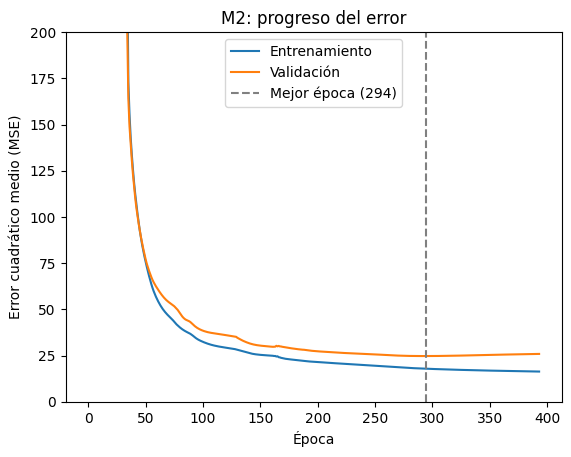

In [8]:
tf.keras.utils.set_random_seed(42)

# M2: 9 entradas -> 16 (tanh) -> 8 (tanh) -> 1 salida (lineal)
m2 = tf.keras.Sequential([
    tf.keras.Input(shape=(9,)),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(8, activation='tanh'),
    tf.keras.layers.Dense(1)
])

m2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')

# Parada temprana: si validación no mejora en 100 épocas, corta y
# se queda con los pesos de la mejor época
parada = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=100,
                                          restore_best_weights=True)

hist2 = m2.fit(X2_entren, y_entren,
               validation_data=(X2_valid, y_valid),
               epochs=2000, batch_size=32, verbose=0, callbacks=[parada])

mejor = int(np.argmin(hist2.history['val_loss'])) + 1
print('Épocas entrenadas:', len(hist2.history['loss']), '| Mejor época:', mejor)

plt.plot(hist2.history['loss'], label='Entrenamiento')
plt.plot(hist2.history['val_loss'], label='Validación')
plt.axvline(mejor, color='gray', linestyle='--', label=f'Mejor época ({mejor})')
plt.ylim(0, 200)
plt.xlabel('Época')
plt.ylabel('Error cuadrático medio (MSE)')
plt.title('M2: progreso del error')
plt.legend()
plt.show()

In [9]:
tabla_m2 = pd.DataFrame({'Entrenamiento': metricas(m2, X2_entren, y_entren),
                         'Prueba': metricas(m2, X2_prueba, y_prueba)}).round(2)
display(tabla_m2)

# Comparación directa con M1 en el examen final
pd.DataFrame({'M1 (prueba)': tabla_m1['Prueba'],
              'M2 (prueba)': tabla_m2['Prueba']})

,Entrenamiento,Prueba
Error absoluto medio (MPa),2.96,3.92
Error relativo medio (%),10.09,13.79
RMSE (MPa),4.05,5.68
R²,0.94,0.88


,M1 (prueba),M2 (prueba)
Error absoluto medio (MPa),4.36,3.92
Error relativo medio (%),14.55,13.79
RMSE (MPa),6.00,5.68
R²,0.87,0.88


Épocas entrenadas: 194 | Mejor época: 94


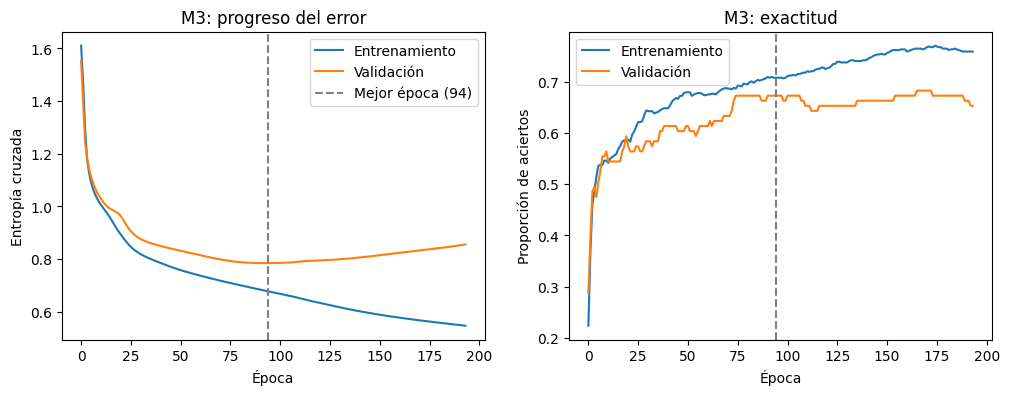

In [10]:
# Las respuestas ahora son clases: C1..C5 pasan a ser los números 0..4
c_entren = entren['clase'].cat.codes.values
c_valid  = valid['clase'].cat.codes.values
c_prueba = prueba['clase'].cat.codes.values

tf.keras.utils.set_random_seed(42)

# M3: 8 entradas -> 16 (tanh) -> 8 (tanh) -> 5 salidas (softmax)
m3 = tf.keras.Sequential([
    tf.keras.Input(shape=(8,)),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(8, activation='tanh'),
    tf.keras.layers.Dense(5, activation='softmax')
])

m3.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
           loss='sparse_categorical_crossentropy', metrics=['accuracy'])

parada3 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=100,
                                           restore_best_weights=True)

hist3 = m3.fit(X_entren, c_entren, validation_data=(X_valid, c_valid),
               epochs=2000, batch_size=32, verbose=0, callbacks=[parada3])

mejor3 = int(np.argmin(hist3.history['val_loss'])) + 1
print('Épocas entrenadas:', len(hist3.history['loss']), '| Mejor época:', mejor3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist3.history['loss'], label='Entrenamiento')
ax1.plot(hist3.history['val_loss'], label='Validación')
ax1.axvline(mejor3, color='gray', linestyle='--', label=f'Mejor época ({mejor3})')
ax1.set_xlabel('Época'); ax1.set_ylabel('Entropía cruzada')
ax1.set_title('M3: progreso del error'); ax1.legend()
ax2.plot(hist3.history['accuracy'], label='Entrenamiento')
ax2.plot(hist3.history['val_accuracy'], label='Validación')
ax2.axvline(mejor3, color='gray', linestyle='--')
ax2.set_xlabel('Época'); ax2.set_ylabel('Proporción de aciertos')
ax2.set_title('M3: exactitud'); ax2.legend()
plt.show()

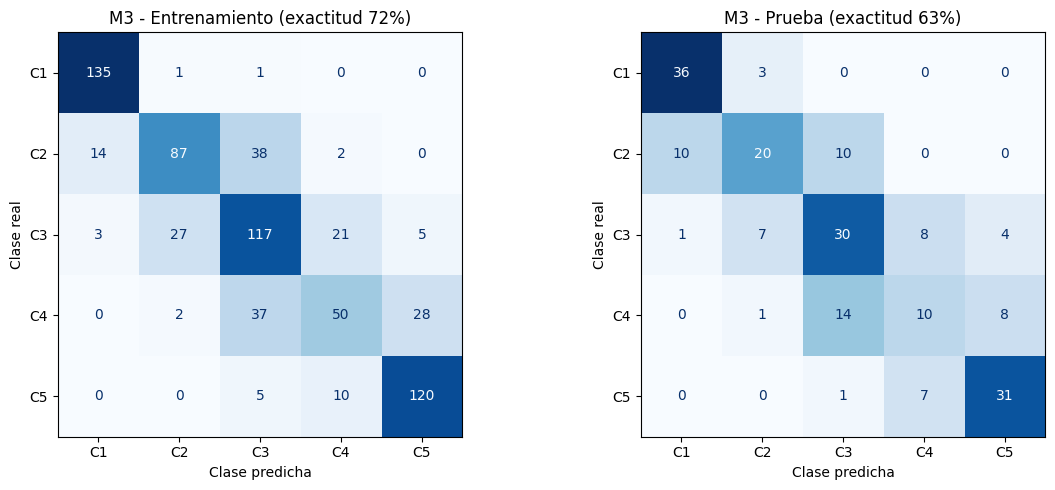

Entrenamiento                         Prueba                 
   Precisión (%) Recuperación (%) Precisión (%) Recuperación (%)
C1          88.8             98.5          76.6             92.3
C2          74.4             61.7          64.5             50.0
C3          59.1             67.6          54.5             60.0
C4          60.2             42.7          40.0             30.3
C5          78.4             88.9          72.1             79.5

In [11]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, accuracy_score)

clases = ['C1', 'C2', 'C3', 'C4', 'C5']

def evaluar_clasificacion(pred, real, titulo, ax):
    ConfusionMatrixDisplay(confusion_matrix(real, pred),
                           display_labels=clases).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{titulo} (exactitud {accuracy_score(real, pred):.0%})')
    ax.set_xlabel('Clase predicha'); ax.set_ylabel('Clase real')
    return pd.DataFrame({'Precisión (%)': 100 * precision_score(real, pred, average=None),
                         'Recuperación (%)': 100 * recall_score(real, pred, average=None)},
                        index=clases)

# La clase predicha es la de mayor probabilidad (argmax)
p3_entren = m3.predict(X_entren, verbose=0).argmax(axis=1)
p3_prueba = m3.predict(X_prueba, verbose=0).argmax(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
t_entren = evaluar_clasificacion(p3_entren, c_entren, 'M3 - Entrenamiento', ax1)
t_prueba = evaluar_clasificacion(p3_prueba, c_prueba, 'M3 - Prueba', ax2)
plt.tight_layout()
plt.show()

pd.concat({'Entrenamiento': t_entren, 'Prueba': t_prueba}, axis=1).round(1)

,Regresión lineal,M1,M2,M3
Error absoluto (MPa),7.78,4.36,3.92,NaN
Error relativo (%),27.52,14.55,13.79,NaN
R²,0.67,0.87,0.88,NaN
Exactitud al clasificar (%),48.76,68.66,72.64,63.18


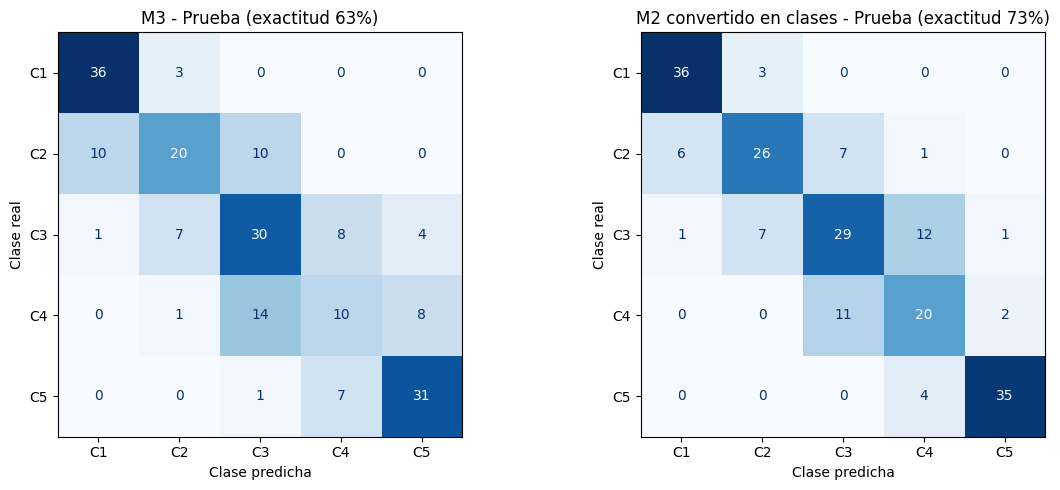

In [12]:
from sklearn.linear_model import LinearRegression

# 1) Línea de base: la regresión lineal de la parcial, con nuestros mismos datos
lineal = LinearRegression().fit(X_entren, y_entren)

# 2) Para convertir MPa en clase (C1..C5 = 0..4)
def a_clase(mpa):
    return pd.cut(mpa, bins=[-np.inf, 20, 30, 40, 50, np.inf],
                  labels=False, right=False).astype(int)

# 3) Tabla resumen: todos los modelos en el grupo de prueba
pred_mpa = {'Regresión lineal': lineal.predict(X_prueba),
            'M1': m1.predict(X_prueba, verbose=0).ravel(),
            'M2': m2.predict(X2_prueba, verbose=0).ravel()}

resumen = {}
for nombre, p in pred_mpa.items():
    resumen[nombre] = {'Error absoluto (MPa)': mean_absolute_error(y_prueba, p),
                       'Error relativo (%)': 100 * mean_absolute_percentage_error(y_prueba, p),
                       'R²': r2_score(y_prueba, p),
                       'Exactitud al clasificar (%)': 100 * accuracy_score(c_prueba, a_clase(p))}
resumen['M3'] = {'Error absoluto (MPa)': np.nan, 'Error relativo (%)': np.nan, 'R²': np.nan,
                 'Exactitud al clasificar (%)': 100 * accuracy_score(c_prueba, p3_prueba)}
display(pd.DataFrame(resumen).round(2))

# 4) M3 contra M2 convertido en clases, lado a lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
evaluar_clasificacion(p3_prueba, c_prueba, 'M3 - Prueba', ax1)
t_m2c = evaluar_clasificacion(a_clase(pred_mpa['M2']), c_prueba, 'M2 convertido en clases - Prueba', ax2)
plt.tight_layout()
plt.show()